In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import xgboost as xgb

import matplotlib.pyplot as plt
import seaborn as sns

import joblib  

In [2]:

file_path = "../data/car_sales_preprocessed_2.csv"

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())


Dataset shape: (761973, 236)
Columns: ['quarter', 'Brand_LE', 'Model_LE', 'Body Type_LE', 'Year_2022', 'Year_2023', 'Gov_اسيوط', 'Gov_الاسكندرية', 'Gov_الاسماعيلية', 'Gov_الاقصر', 'Gov_البحر الاحمر', 'Gov_البحيرة', 'Gov_الجيزة', 'Gov_الدقهلية', 'Gov_السويس', 'Gov_الشرقية', 'Gov_الغربية', 'Gov_الفيوم', 'Gov_القاهرة', 'Gov_القليوبية', 'Gov_المنوفية', 'Gov_المنيا', 'Gov_الوادي الجديد', 'Gov_بني سويف', 'Gov_بورسعيد', 'Gov_جنوب سيناء', 'Gov_دمياط', 'Gov_سوهاج', 'Gov_شمال سيناء', 'Gov_قنا', 'Gov_كفر الشيخ', 'Gov_مرسي مطروح', 'TU_مجلس الدولة', 'TU_منفذ جمـارك القاهـرة - تسيير', 'TU_منفذ مرور موانى بورسعيد', 'TU_منفذ ميناء الاسكندرية', 'TU_منفذ ميناء السويس', 'TU_منفذ ميناء سفاجا', 'TU_منفذ ميناء نويبـــع', 'TU_وحدة القوات المسلحـة', 'TU_وحدة خدمات الشرطة', 'TU_وحدة دمياط الجديدة', 'TU_وحدة عين الصيــرة', 'TU_وحدة ق.م مصطفى كامل', 'TU_وحدة مرور 6 اكتوبر', 'TU_وحدة مرور أبو المطامير', 'TU_وحدة مرور أبوحماد', 'TU_وحدة مرور أبوكبير', 'TU_وحدة مرور أسوان', 'TU_وحدة مرور أوسيـم', 'TU_وحدة مرور إدفو

In [3]:
# Target
y = df["Brand_LE"]

# Features: drop Brand_LE (target) and Model_LE (strongly associated with brand)
X = df.drop(columns=["Brand_LE", "Model_LE"])

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (761973, 234)
Target shape: (761973,)


In [4]:
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.25, random_state=42, stratify=y_trainval
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Train: (457183, 234)
Validation: (152395, 234)
Test: (152395, 234)


In [5]:
xgb_model = xgb.XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    random_state=42,
    use_label_encoder=False,
    eval_metric="mlogloss"
)

xgb_model.fit(
    X_train, y_train
)

print("🎯 XGBoost training complete!")


.../site-packages/xgboost/training.py:199: UserWarning: [20:09:14] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


🎯 XGBoost training complete!


📊 Test Accuracy: 0.15697365399127267

📋 Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         2
           1       0.00      0.00      0.00       452
           2       0.00      0.00      0.00        62
           3       0.42      0.03      0.05      2477
           4       1.00      0.00      0.00      1326
           5       0.31      0.04      0.06      2562
           6       0.59      0.01      0.02      2299
           7       0.00      0.00      0.00       155
           8       0.00      0.00      0.00       315
           9       0.00      0.00      0.00       209
          10       0.00      0.00      0.00         6
          11       0.51      0.01      0.02      3299
          12       0.16      0.03      0.05       437
          13       0.12      0.61      0.20     10435
          14       0.31      0.24      0.27      4956
          15       0.00      0.00      0.00         3
          16      

.../site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
.../site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
.../site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


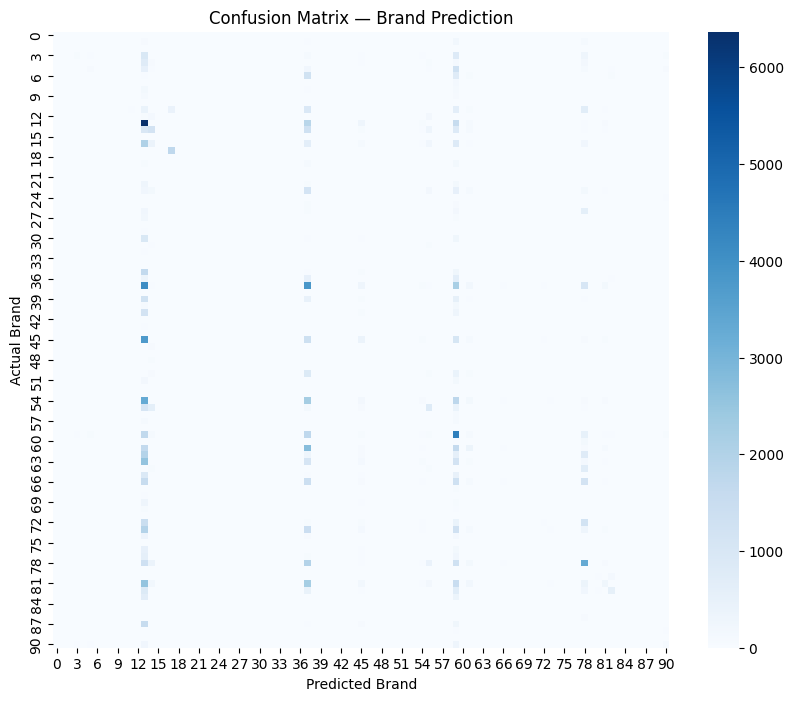

In [6]:
y_pred = xgb_model.predict(X_test)

print("📊 Test Accuracy:", accuracy_score(y_test, y_pred))
print("\n📋 Classification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix
plt.figure(figsize=(10,8))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, cmap="Blues", square=True)
plt.title("Confusion Matrix — Brand Prediction")
plt.xlabel("Predicted Brand")
plt.ylabel("Actual Brand")
plt.show()


<Figure size 1000x600 with 0 Axes>

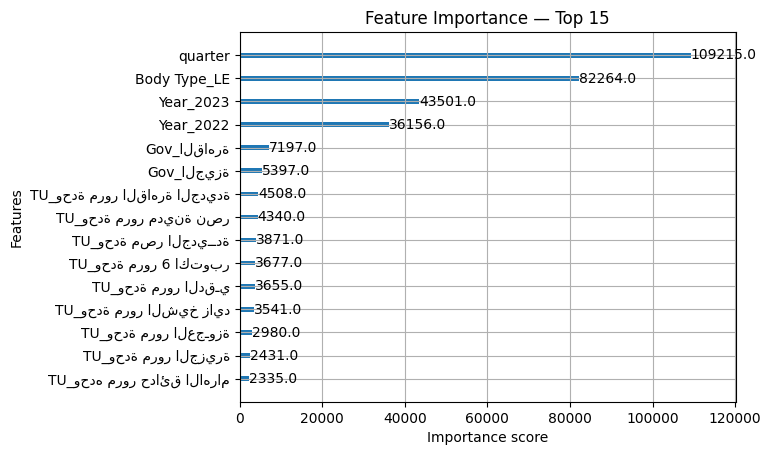

In [7]:
plt.figure(figsize=(10, 6))
xgb.plot_importance(xgb_model, max_num_features=15)
plt.title("Feature Importance — Top 15")
plt.show()

In [ ]:
model_filename = "../models/xgb_top_brand.joblib"
joblib.dump(xgb_model, model_filename)
print(f"✅ Saved XGBoost model to: {model_filename}")